# GEnKF

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from rainfall import *
from enkf import *

In [3]:
data = load_data("./data/rainfall.pt")
theta = data["theta"]
x = data["x"]
stations = data["stations"]
y = data["y"]
z = data["z"]
meta = data["meta"]

In [4]:
torch.manual_seed(548)
particles, log_weights = genkf(stations, z, n=100, T=10)

In [5]:
theta[10]

tensor(2.4623)

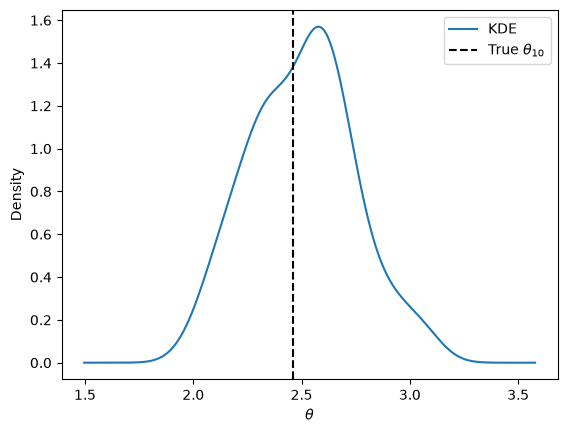

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

t = 10
thetas = torch.stack([torch.as_tensor(p[0]) for p in particles]).numpy()
true_theta = theta[t].item()
kde = gaussian_kde(thetas)
grid = np.linspace(min(thetas.min(), true_theta) - 0.5,
                   max(thetas.max(), true_theta) + 0.5, 500)
plt.plot(grid, kde(grid), label="KDE")
plt.axvline(true_theta, color="k", linestyle="--", label=rf"True $\theta_{{{t}}}$")
plt.xlabel(r"$\theta$")
plt.ylabel("Density")
plt.legend()
plt.show()

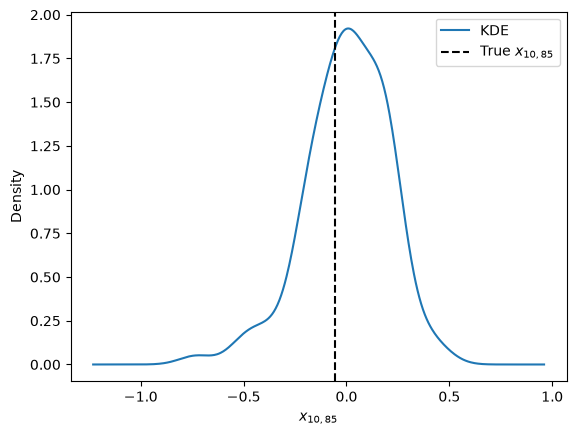

In [7]:
# Posterior samples of x are the ensemble members, which are equally weighted
X = torch.stack([p[1] for p in particles]).numpy() # (n, grid)

def plot_kde(samples, true_value, label):
    kde = gaussian_kde(samples)
    grid = np.linspace(min(samples.min(), true_value) - 0.5,
                       max(samples.max(), true_value) + 0.5, 500)
    plt.plot(grid, kde(grid), label="KDE")
    plt.axvline(true_value, color="k", linestyle="--", label=f"True {label}")
    plt.xlabel(label)
    plt.ylabel("Density")
    plt.legend()
    plt.show()

rng = np.random.default_rng(0)
k = rng.integers(X.shape[1])
plot_kde(X[:, k], x[t, k].item(), rf"$x_{{{t},{k}}}$")

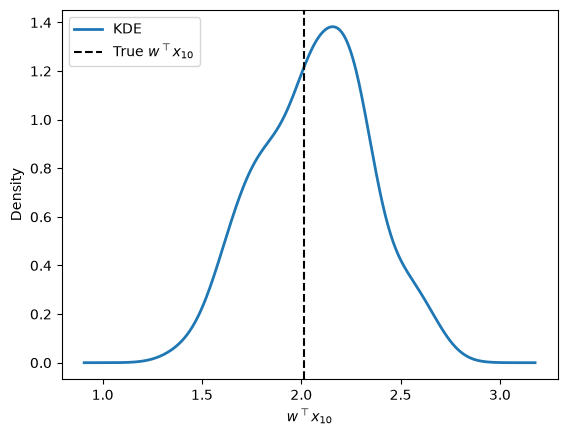

In [8]:
w = rng.standard_normal(X.shape[1])
w /= np.linalg.norm(w)
proj = X @ w # (n,)
true_proj = float(x[t].numpy() @ w)

kde = gaussian_kde(proj)
grid = np.linspace(min(proj.min(), true_proj) - 0.5,
                   max(proj.max(), true_proj) + 0.5, 500)
plt.plot(grid, kde(grid), color="C0", linewidth=2, label="KDE")
plt.axvline(true_proj, color="k", linestyle="--", label=rf"True $w^\top x_{{{t}}}$")
plt.xlabel(rf"$w^\top x_{{{t}}}$")
plt.ylabel("Density")
plt.legend(loc="upper left")
plt.show()

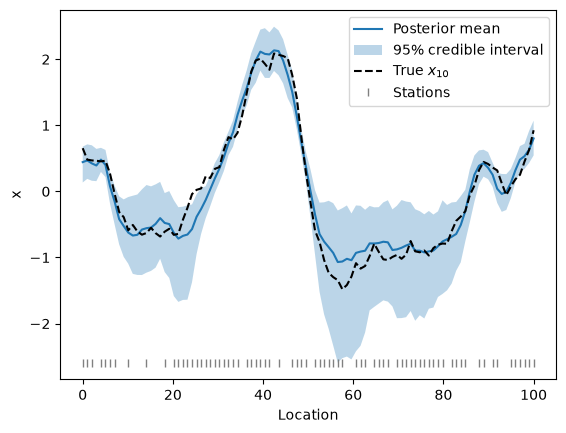

In [9]:
location = np.linspace(0, 100, X.shape[1]) # grid used by draw_prior_state
post_mean = X.mean(axis=0)
lower, upper = np.quantile(X, [0.025, 0.975], axis=0)

plt.plot(location, post_mean, label="Posterior mean")
plt.fill_between(location, lower, upper, alpha=0.3, label="95% credible interval")
plt.plot(location, x[t].numpy(), "k--", label=rf"True $x_{{{t}}}$")
plt.plot(location[stations], np.full(len(stations), lower.min()), "|", color="gray",
         label="Stations")
plt.xlabel("Location")
plt.ylabel("x")
plt.legend()
plt.show()